In [1]:
import os
import sys
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils.plotting import plot_movement_data
from utils.plotting import plot_movement_data_3d
from utils.helper_functions import get_smart_retail_dataset
from utils.constants import Configs
from utils.helper_functions import load_outlier_data

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


SMART_RETAIL_OUTLIERS_LEFT_PATH: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
SMART_RETAIL_OUTLIERS_RIGHT_PATH: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv


## Get Inliers

In [ ]:
def read_files(files):
    dfs = []

    for lf in files:
        df = pd.read_csv(lf, delimiter=';')
        dfs.append(df)

    df = pd.concat(dfs, ignore_index=True)
    df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
    df = df.ffill().bfill()

    mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Park'} 
    df['movLabel'] = df['movType'].map(mapa_mov)
    
    return df

In [3]:
left_files_inliers_path = glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_left_Tasks.csv')
right_files_inliers_path = glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_right_Tasks.csv')

df_inliers_left = read_files(left_files_inliers_path)
df_inliers_right = read_files(right_files_inliers_path)


left_files_original = Configs.SMART_RETAIL_LEFT_FILES
right_files_original = Configs.SMART_RETAIL_RIGHT_FILES
df_original_left = read_files(left_files_original)
df_original_right = read_files(right_files_original)

In [4]:
df_original_left

,sub,repID,movID,movType,step,xs,ys,zs,xe,ye,ze,xw,yw,zw,vel,acc,t,k,movLabel
0,1,1,1,0,1,2.357,-190.389,1448.24,28.459,-172.787,1128.64,4.099,-174.912,867.136,0.314419,0.368028,-1.387820,2.618244,Pick
1,1,1,1,0,2,3.182,-192.290,1447.52,27.931,-173.406,1127.87,-1.009,-179.932,866.915,0.310089,0.658925,-1.732887,4.893958,Pick
2,1,1,1,0,3,3.622,-193.419,1446.96,27.135,-174.201,1127.25,-4.855,-181.429,866.665,0.299228,1.044781,-2.463496,8.587954,Pick
3,1,1,1,0,4,3.895,-194.151,1446.52,26.100,-174.614,1126.73,-9.062,-182.366,866.570,0.286628,1.055988,-3.797109,9.614970,Pick
4,1,1,1,0,5,4.207,-194.841,1446.10,25.032,-174.843,1126.25,-13.354,-183.134,866.558,0.275769,0.841129,-3.507823,7.997407,Pick
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104785,19,5,12,6,77,-46.419,-134.236,1438.80,41.071,-169.316,1154.71,-17.169,-177.989,917.255,0.071203,1.132732,79.768574,189.288878,Park
104786,19,5,12,6,78,-45.925,-133.837,1438.89,41.554,-169.092,1154.82,-15.883,-177.540,917.160,0.062902,1.126195,78.147067,265.307355,Park
104787,19,5,12,6,79,-45.266,-133.727,1438.92,42.020,-169.202,1154.82,-14.582,-177.604,916.956,0.057782,1.067749,86.567901,313.191269,Park
104788,19,5,12,6,80,-44.521,-133.970,1438.89,42.507,-169.484,1154.71,-13.495,-177.827,916.705,0.055464,0.966164,102.557158,313.298087,Park


In [5]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


### Discard Subject 13

In [ ]:
# Discard from dataset
df_original_left.drop(df_original_left[df_original_left['sub']== 13].index, inplace=True)
df_original_right.drop(df_original_right[df_original_right['sub']== 13].index, inplace=True)

df_inliers_left.drop(df_inliers_left[df_inliers_left['sub']== 13].index, inplace=True)
df_inliers_right.drop(df_inliers_right[df_inliers_right['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [19]:
print(df_original_right)

        sub  repID  movID  movType  step      xs       ys       zs      xe  \
0         1      1      1        0     1   9.114  178.102  1464.60  18.750   
1         1      1      1        0     2   9.242  178.003  1464.84  19.079   
2         1      1      1        0     3   9.318  177.868  1464.95  19.352   
3         1      1      1        0     4   9.419  177.683  1465.19  19.810   
4         1      1      1        0     5   9.456  177.472  1465.40  20.020   
...     ...    ...    ...      ...   ...     ...      ...      ...     ...   
105115   19      5     12        6    97 -44.090  166.209  1429.73 -16.038   
105116   19      5     12        6    98 -42.117  167.198  1429.01 -14.766   
105117   19      5     12        6    99 -40.137  168.223  1428.28 -13.263   
105118   19      5     12        6   100 -37.988  169.216  1427.59 -11.416   
105119   19      5     12        6   101 -35.787  170.140  1426.97  -9.414   

             ye       ze       xw       yw       zw       vel  

## Get inliers from original dataset
The inliers present in the inliers files have prepocessed data (homogenized coordinates and homongenized steps). This will create inliers with the original data

In [10]:
# Extract unique identifiers from the inliers dataset
inliers_metadata = pd.concat([df_inliers_left[['sub', 'repID']], df_inliers_right[['sub', 'repID']]], ignore_index=True).drop_duplicates()

# Filter the original dataset using an INNER JOIN
df_original_left_filtered = pd.merge(df_original_left, inliers_metadata, on=['sub', 'repID'], how='inner')
df_original_right_filtered = pd.merge(df_original_right, inliers_metadata, on=['sub', 'repID'], how='inner')

## Plot differences between inliers exported and inliers filtered from the original dataset


--- A gerar gráfico 3D para a Mão ESQUERDA (Exported Inliers) ---


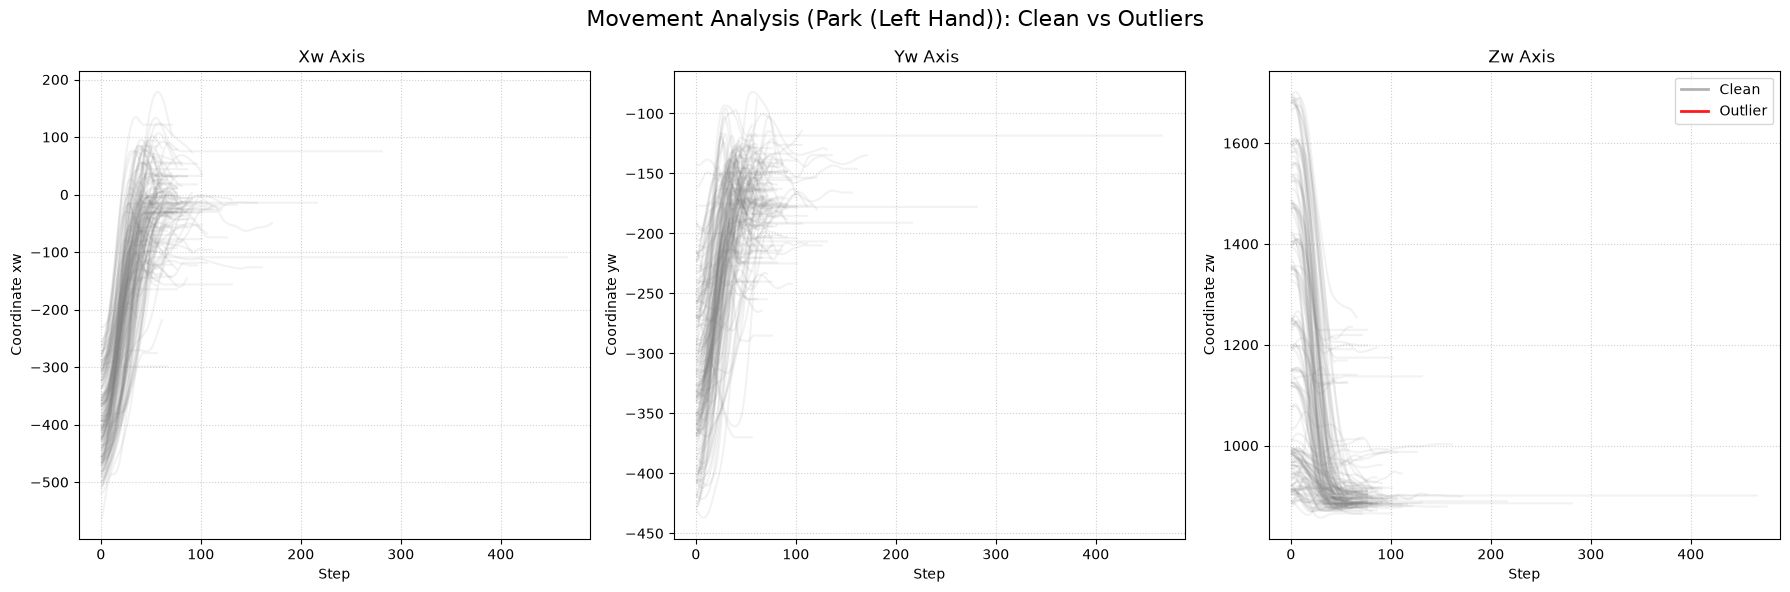


--- A gerar gráfico 3D para a Mão DIREITA (Exported Inliers) ---


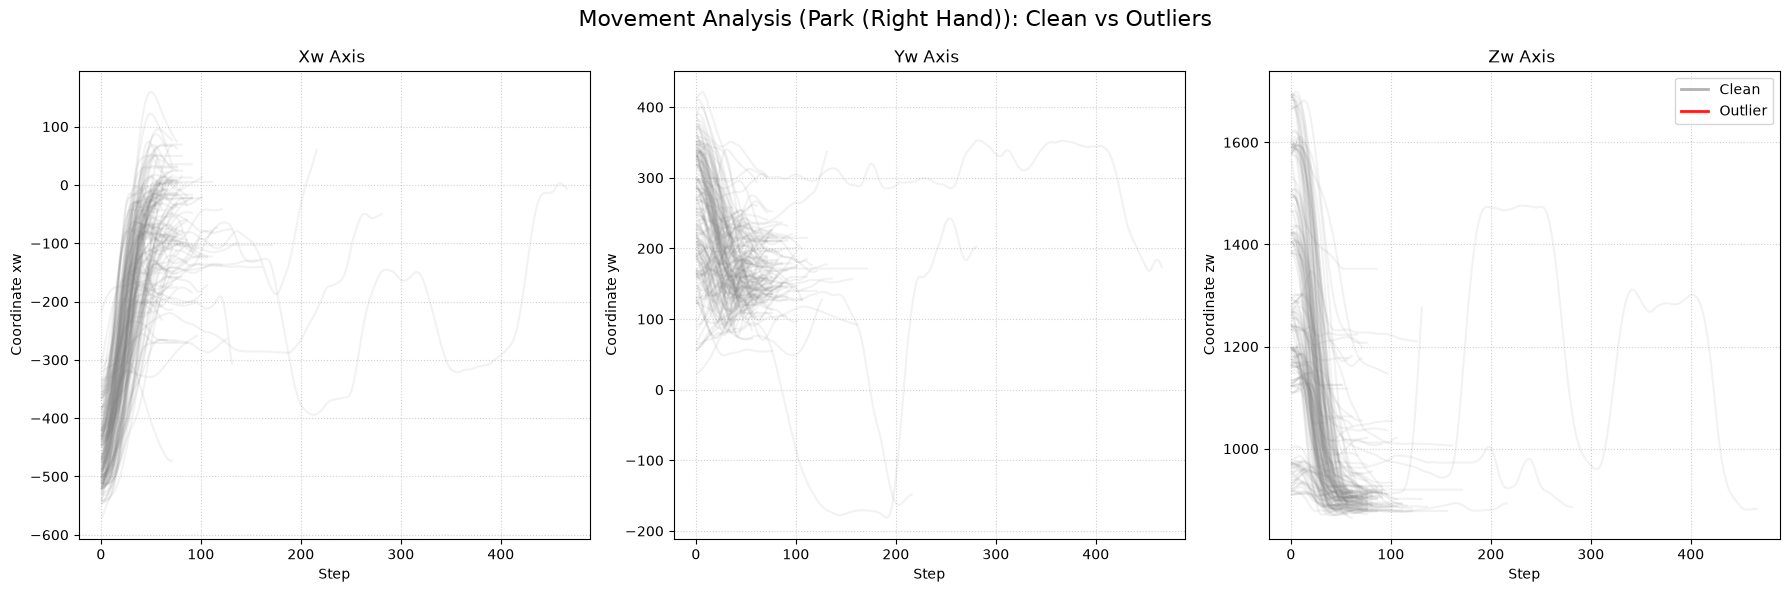

In [20]:
# ==========================================
# Exported Inliers from Plot_Validation.ipynb
# ==========================================


TARGET_MOV = 'Park' 

# Filter inliers by TARGET_MOV for both left and right hands
inliers_left_temp = df_inliers_left[df_inliers_left['movLabel'] == TARGET_MOV].copy()
inliers_right_temp = df_inliers_right[df_inliers_right['movLabel'] == TARGET_MOV].copy()
# original_inliers_left_temp = df_original_left[df_original_left['movLabel'] == TARGET_MOV].copy()
# original_inliers_right_temp = df_original_right[df_original_right['movLabel'] == TARGET_MOV].copy()

inliers_left_temp['temp_key'] = inliers_left_temp['sub'].astype(str) + "_" + \
                           inliers_left_temp['repID'].astype(str) + "_" + \
                           inliers_left_temp['movID'].astype(str)

inliers_right_temp['temp_key'] = inliers_right_temp['sub'].astype(str) + "_" + \
                           inliers_right_temp['repID'].astype(str) + "_" + \
                           inliers_right_temp['movID'].astype(str)

empty_outliers_left = pd.DataFrame(columns=inliers_left_temp.columns)

print("\n--- A gerar gráfico 3D para a Mão ESQUERDA (Exported Inliers) ---")
plot_movement_data(
    clean_data=inliers_left_temp,       
    outlier_data=empty_outliers_left,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw', 'yw', 'zw'] 
)

print("\n--- A gerar gráfico 3D para a Mão DIREITA (Exported Inliers) ---")
plot_movement_data(
    clean_data=inliers_right_temp,       
    outlier_data=empty_outliers_left,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw', 'yw', 'zw'] 
)


--- A gerar gráfico 3D para a Mão ESQUERDA (Original dataset Inliers) ---


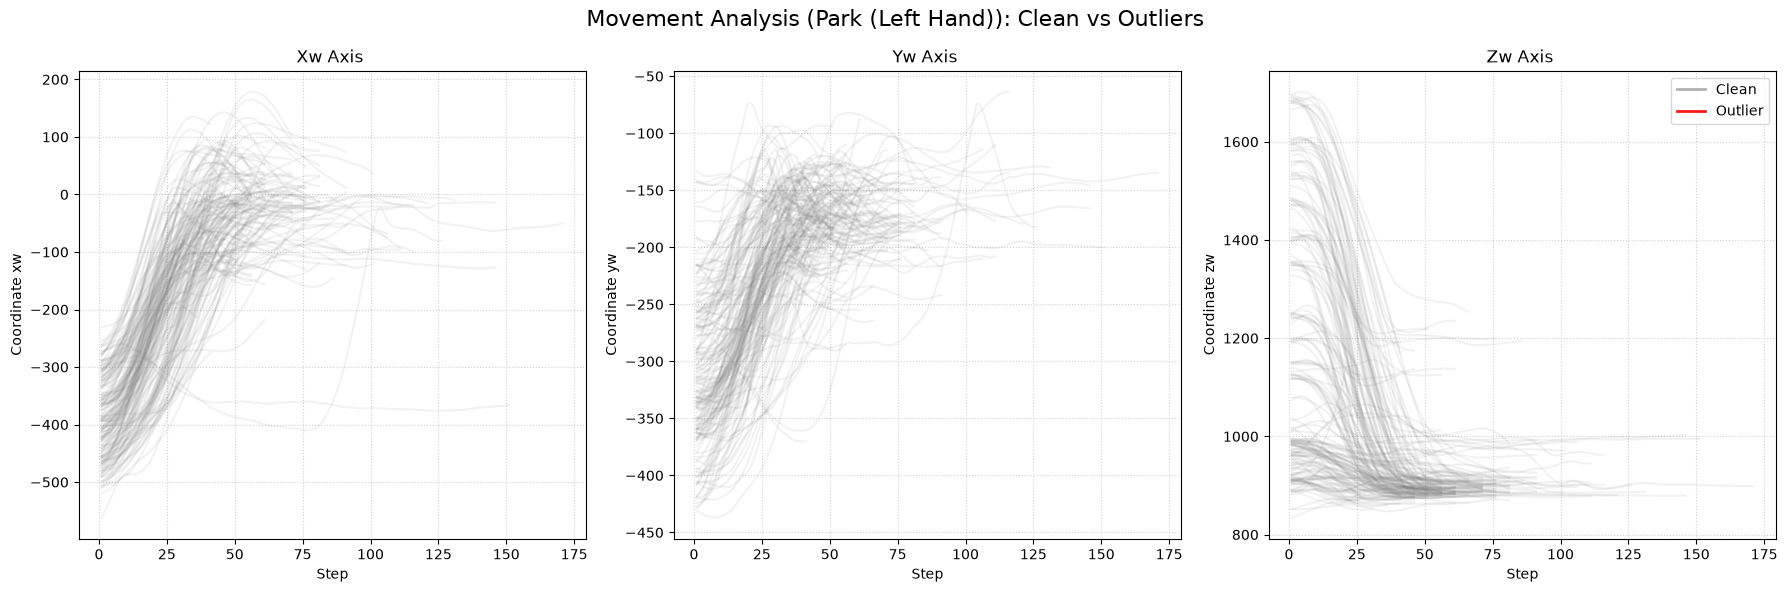


--- A gerar gráfico 3D para a Mão DIREITA (Original dataset Inliers) ---


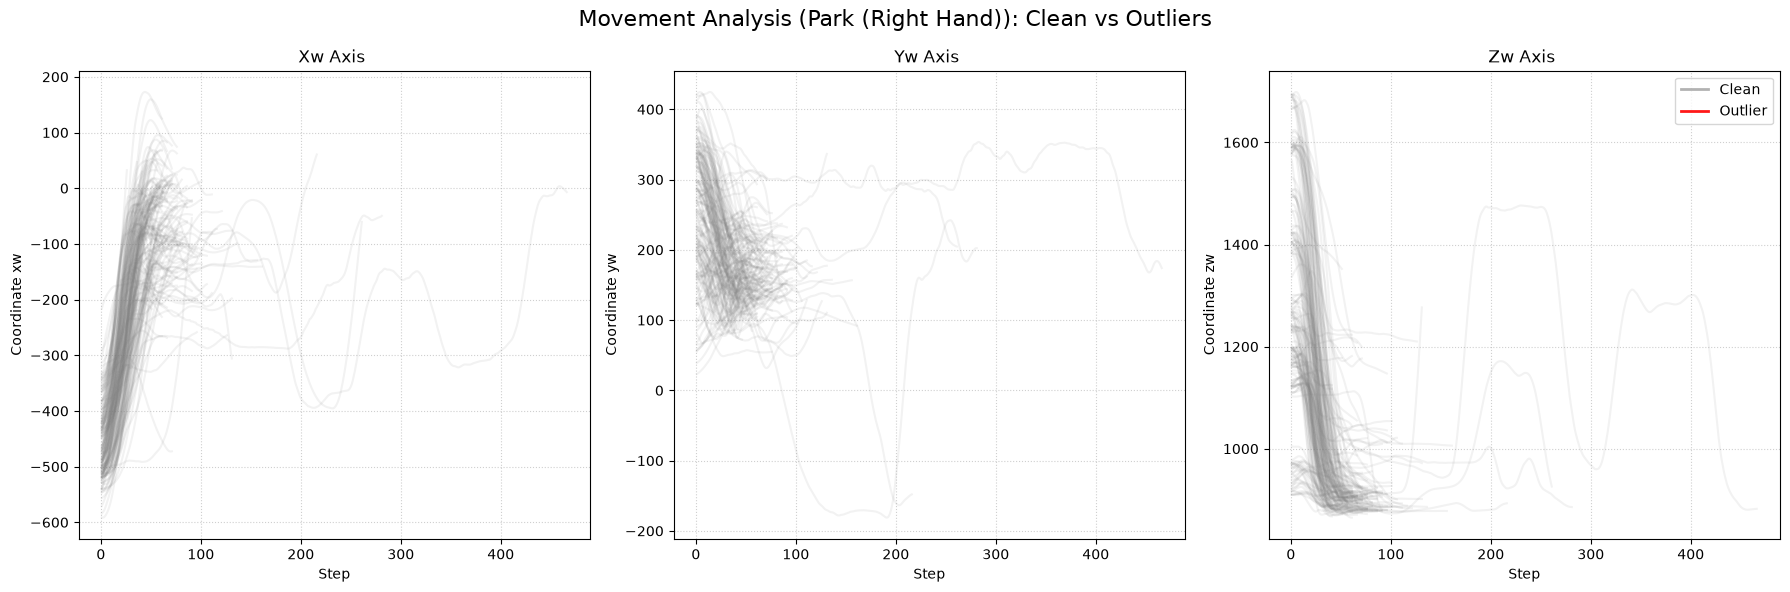

In [21]:
# ==========================================
# Inliers filtered from the original dataset 
# ==========================================


TARGET_MOV = 'Park' 

# Filter inliers by TARGET_MOV for both left and right hands
original_inliers_left_temp = df_original_left[df_original_left['movLabel'] == TARGET_MOV].copy()
original_inliers_right_temp = df_original_right[df_original_right['movLabel'] == TARGET_MOV].copy()

original_inliers_left_temp['temp_key'] = original_inliers_left_temp['sub'].astype(str) + "_" + \
                                   original_inliers_left_temp['repID'].astype(str) + "_" + \
                                   original_inliers_left_temp['movID'].astype(str)

original_inliers_right_temp['temp_key'] = original_inliers_right_temp['sub'].astype(str) + "_" + \
                                    original_inliers_right_temp['repID'].astype(str) + "_" + \
                                    original_inliers_right_temp['movID'].astype(str)

empty_outliers_left = pd.DataFrame(columns=original_inliers_left_temp.columns)

print("\n--- A gerar gráfico 3D para a Mão ESQUERDA (Original dataset Inliers) ---")
plot_movement_data(
    clean_data=original_inliers_left_temp,       
    outlier_data=empty_outliers_left,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw', 'yw', 'zw'] 
)

print("\n--- A gerar gráfico 3D para a Mão DIREITA (Original dataset Inliers) ---")
plot_movement_data(
    clean_data=original_inliers_right_temp,       
    outlier_data=empty_outliers_left,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw', 'yw', 'zw'] 
)

## Análise de Número de repetições por sujeito

In [ ]:
df_repID_distinct = df_raw_filtered.drop_duplicates(subset=['sub', 'repID']).copy()
df_repID_distinct

,sub,repID,movID,movType,step,xs_L,ys_L,zs_L,xe_L,ye_L,...,ze_R,xw_R,yw_R,zw_R,vel_R,acc_R,k_R,movLabel,jerk_L,jerk_R
0,1,3,1,0,1,26.619,-181.212,1450.62,64.452,-171.299,...,1149.19,34.741,162.555,886.977,0.200493,0.186663,3.223598,Pick,0.0,0.0
1084,1,5,1,0,1,22.093,-173.553,1455.73,91.834,-184.942,...,1152.75,41.785,153.200,904.406,0.319639,0.297177,1.156640,Pick,0.0,0.0
2413,2,1,1,0,1,45.627,-188.545,1431.28,38.496,-203.739,...,1126.39,-71.871,122.020,881.506,0.072408,0.060324,9.458010,Pick,0.0,0.0
3567,2,2,1,0,1,68.743,-186.537,1429.92,70.738,-190.363,...,1126.11,-100.231,57.195,887.123,0.065573,0.208944,46.050993,Pick,0.0,0.0
4551,2,4,1,0,1,40.913,-192.195,1433.71,48.086,-196.624,...,1129.99,-94.133,98.256,890.090,0.266432,0.212143,2.302399,Pick,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79651,19,1,1,0,1,7.850,-146.921,1439.62,45.952,-173.414,...,1127.69,16.786,135.164,888.178,0.094324,0.423892,40.550795,Pick,0.0,0.0
80623,19,2,1,0,1,-11.690,-136.563,1441.41,53.419,-157.570,...,1124.97,31.199,117.196,885.142,0.035298,0.075492,19.159631,Pick,0.0,0.0
81600,19,3,1,0,1,-24.292,-142.985,1440.05,37.869,-160.245,...,1123.91,6.675,109.750,884.309,0.119771,0.512719,33.808061,Pick,0.0,0.0
82587,19,4,1,0,1,-14.947,-154.657,1434.29,42.624,-157.514,...,1124.08,20.994,116.277,883.109,0.026221,0.257527,60.308934,Pick,0.0,0.0


<Axes: xlabel='sub', ylabel='count'>

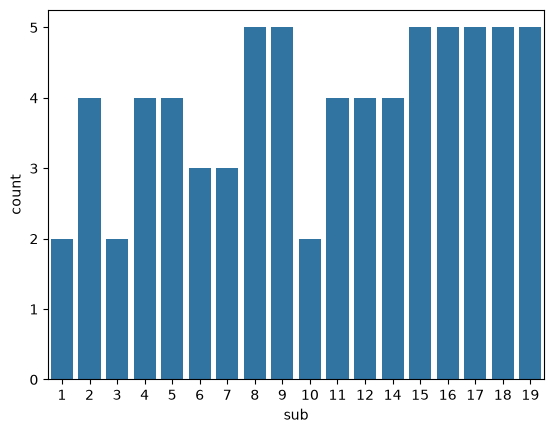

In [18]:
counts = df_repID_distinct.groupby('sub')['repID'].count().reset_index(name='count')

sns.barplot(
    data=counts,
    x='sub',
    y='count',
)

In [123]:
print("RepID count: {}".format(counts['count'].sum()))

RepID count: 71


In [23]:
def get_step_counts(df_left: pd.DataFrame, df_right: pd.DataFrame, prefix: str) -> pd.DataFrame:
    """
    Groups the dataframe by trajectory identifiers and counts the number of steps (rows).
    """
    left_counts = df_left.groupby(['sub', 'repID', 'movID']).size().reset_index(name=f'{prefix}_left_steps')
    right_counts = df_right.groupby(['sub', 'repID', 'movID']).size().reset_index(name=f'{prefix}_right_steps')
    
    df_counts = pd.merge(left_counts, right_counts, on=['sub', 'repID', 'movID'], how='inner')
    return df_counts

def plot_steps_comparison(df_raw_counts: pd.DataFrame, df_inlier_counts: pd.DataFrame):
    """
    Plots a comparison of Left vs Right arm steps for original and interpolated data.
    """
    print("Generating comparison plots...")
    
    df_lengths = pd.merge(df_raw_counts, df_inlier_counts, on=['sub', 'repID', 'movID'], how='inner')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    max_val = max(
        df_lengths['raw_left_steps'].max(), 
        df_lengths['raw_right_steps'].max(),
        df_lengths['inlier_left_steps'].max()
    ) + 10

    # Plot 1: Original Inliers Data (Temporal Mismatch)
    ax1.scatter(
        df_lengths['raw_left_steps'], 
        df_lengths['raw_right_steps'], 
        alpha=0.6, color='red', edgecolor='k', s=60
    )
    
    ax1.plot([0, max_val], [0, max_val], 'k--', label='Perfect Sync (Left = Right)')
    
    ax1.set_title('Original Inliers (Raw Unpadded Data)', fontsize=12)
    ax1.set_xlabel('Left Arm (Number of Steps)')
    ax1.set_ylabel('Right Arm (Number of Steps)')
    ax1.set_xlim(0, max_val)
    ax1.set_ylim(0, max_val)
    ax1.legend()
    ax1.grid(True, linestyle=':', alpha=0.7)

    # Plot 2: Exported Inliers Data (Interpolated/Padded)
    ax2.scatter(
        df_lengths['inlier_left_steps'], 
        df_lengths['inlier_right_steps'], 
        alpha=0.6, color='blue', edgecolor='k', s=60
    )
    
    ax2.plot([0, max_val], [0, max_val], 'k--', label='Perfect Sync (Left = Right)')
    
    ax2.set_title('Exported Inliers (Padded for ML Pipeline)', fontsize=12)
    ax2.set_xlabel('Left Arm (Number of Steps)')
    ax2.set_ylabel('Right Arm (Number of Steps)')
    ax2.set_xlim(0, max_val)
    ax2.set_ylim(0, max_val)
    ax2.legend()
    ax2.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.show()

Generating comparison plots...


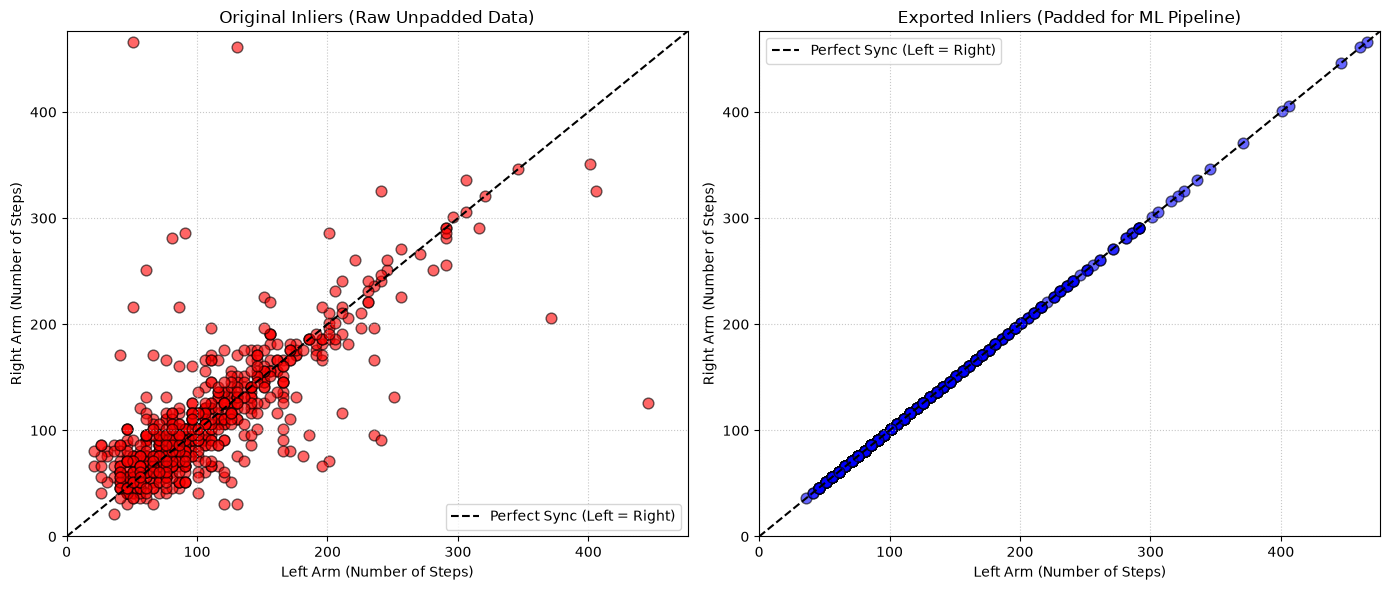

In [24]:
# Get step counts for both datasets
df_raw_counts = get_step_counts(df_original_left_filtered, df_original_right_filtered, 'raw')
df_inlier_counts = get_step_counts(df_inliers_left, df_inliers_right, 'inlier')

# Generate comparison plot
plot_steps_comparison(df_raw_counts, df_inlier_counts)

## Export Data following Daniel original csv files

In [ ]:
def export_gold_standard_datasets(df_left: pd.DataFrame, df_right: pd.DataFrame, output_dir: str):
    """
    Exports the filtered raw datasets into separate CSV files per subject and arm.
    """
    print("\n--- EXPORTING GOLD STANDARD FILES BY SUBJECT AND ARM ---")
    
    os.makedirs(output_dir, exist_ok=True)
    
    final_signature = [
        'sub', 'repID', 'movID', 'movType', 'step', 
        'xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw', 
        'vel', 'acc', 't', 'k'
    ]
    
    int_columns = ['sub', 'repID', 'movID', 'movType', 'step']
    
    # Force identification columns to integer (removes .0 decimals)
    for col in int_columns:
        if col in df_left.columns:
            df_left[col] = df_left[col].astype(int)
        if col in df_right.columns:
            df_right[col] = df_right[col].astype(int)

    valid_subjects = sorted(df_left['sub'].unique())
    
    for subject in valid_subjects:
        # Process Left Arm
        sub_left = df_left[df_left['sub'] == subject].copy()
        cols_l = [c for c in final_signature if c in sub_left.columns]
        sub_left = sub_left[cols_l]
        
        left_filename = f"Subject{subject}_left_Tasks.csv"
        sub_left.to_csv(os.path.join(output_dir, left_filename), index=False, sep=';')
        
        # Process Right Arm
        sub_right = df_right[df_right['sub'] == subject].copy()
        cols_r = [c for c in final_signature if c in sub_right.columns]
        sub_right = sub_right[cols_r]
        
        right_filename = f"Subject{subject}_right_Tasks.csv"
        sub_right.to_csv(os.path.join(output_dir, right_filename), index=False, sep=';')

    print(f"Export completed! Generated Left and Right files for {len(valid_subjects)} subjects.")
    print(f"Saved at: {output_dir}")

export_gold_standard_datasets(
    df_left=df_original_left_filtered, 
    df_right=df_original_right_filtered, 
    output_dir="/home/hugo-guimar-es/Desktop/Inliers_SmartRetail/"
)


--- EXPORTING GOLD STANDARD FILES BY SUBJECT AND ARM ---
Export completed! Generated Left and Right files for 18 subjects.
Saved at: /home/hugo-guimar-es/Desktop/Inliers_SmartRetail/
